# Neural Operators for 1D Steady Diffusion

**Muhammed Fawzan** · Supervisor: Prof. C. Annavarapu, Dept. of Civil Engineering, IIT Madras

June–August 2026

---

## Governing equation

$$-\frac{d}{dx}\left[\alpha(x)\,\frac{dp}{dx}\right] = f(x), \qquad x \in \Omega = (0,1), \qquad p(0)=p(1)=0$$

where $\alpha$ is the diffusion coefficient, $f$ the source and $p$ the solution field.
When an interface is present at $x=0.5$, the domain splits into $\Omega_1=(0,0.5)$ and
$\Omega_2=(0.5,1)$ and two further conditions hold:

$$[\![p]\!] = 0 \qquad\text{and}\qquad [\![\alpha\, p']\!] = 0 \qquad \text{at } x = 0.5$$

The goal is to learn **operators** of this equation: maps from an input *function* to the
solution *function*, so that a new instance is solved by a forward pass rather than by
retraining.

## The ladder

| Step | $\alpha$ | operator input | interface | architecture | reference data |
|---|---|---|---|---|---|
| 1a | constant, fixed | $f$ = constant, varied | no | DeepONet | analytical |
| 1b | constant, fixed | $f(x)$, varied | no | DeepONet | `scipy.solve_bvp` |
| 2a | constant, varied | — ($f=1$ fixed) | no | DeepONet | analytical |
| 2b | $\alpha(x)$, varied | — ($f=1$ fixed) | no | DeepONet | `scipy.solve_bvp` |
| 3b | $\alpha_1 \neq \alpha_2$, piecewise const. | $(\alpha_1,\alpha_2)$ | yes | $\phi$-DeepONet | analytical (Hansbo) |
| 3+ | $\alpha(x)$ + jump | $\alpha(x)$ | yes | $\phi$-DeepONet | quadrature / FEM |

Step 3a ($\alpha_1=\alpha_2$) is omitted: with no contrast the interface conditions are
satisfied identically and the problem reduces to Step 2a.

All models are trained **physics-informed**: the loss is the PDE residual (plus boundary and
interface terms), never a fit to precomputed solutions. Analytical formulae and
`scipy.solve_bvp` are used *only* to measure error on held-out test samples.

---
# Step 1a: DeepONet

With $f$ and $\alpha$ both constant the solution is available in closed form,

$$p(x) = \frac{f\,x(1-x)}{2\alpha},$$

obtained by integrating $p'' = -f/\alpha$ twice and applying $p(0)=p(1)=0$.

The branch network sees $f$ sampled at 10 sensor points (all equal, since $f$ is a
scalar); the trunk sees the query coordinate $x$; the output is their dot product. The input
function space is `PowerSeries(N=1)`, which draws a single coefficient uniformly from $[-1,1]$.


**Note on relative error.** `PowerSeries` samples $f$ across zero, so a test sample with
$f \approx 0$ has $\|p_{\text{true}}\| \approx 0$ and its *relative* error blows up. The mean
per-sample error is therefore dominated by a few near-zero draws; the global relative error
over the whole test set is the honest number to quote.

**Colab notebook:** [https://colab.research.google.com/drive/1v85GnRMjFTv2axZW8y4UylMUmpCpxeM1?usp=sharing]


**Error curve:**

<!-- ![error curve](img/1a_error.png) -->
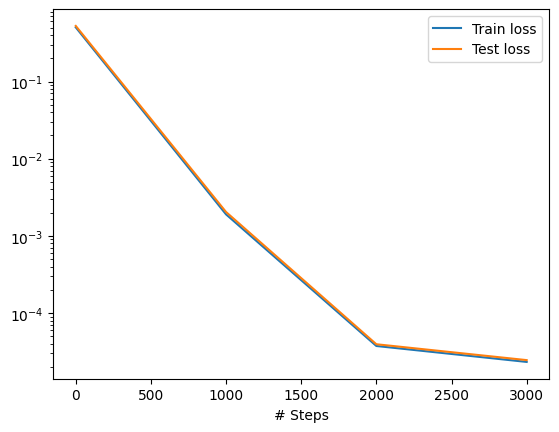

**Representative sample:**

<!-- ![representative sample](img/1a_sample.png) -->
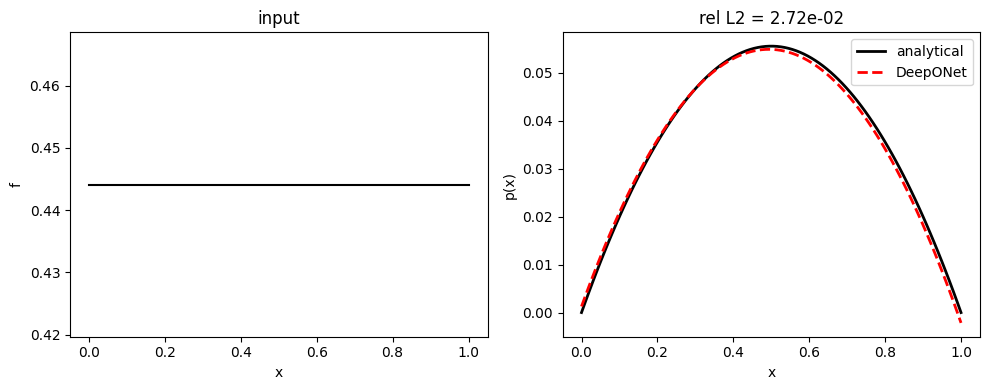

**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 2.35% |
| training samples | 500 |
| iterations | 5000 |

---
# Step 1b: DeepONet, $f(x) \mapsto p$ with spatially varying $f$

**What is new:** the input is now a *function*, so the branch network sees a genuine
discretisation of $f$ rather than a repeated scalar.

**Input functions.** Sampled from a Gaussian random field with squared-exponential kernel,

$$k(x_1,x_2) = \exp\!\left(-\frac{\|x_1-x_2\|^2}{2\ell_s^2}\right), \qquad \ell_s = 0.2,$$

evaluated at 100 sensor points. DeepXDE's `GRF` is zero-mean.

**Reference solutions.** `scipy.solve_bvp`, with the second-order BVP written as the
first-order system

$$y_0' = y_1, \qquad y_1' = -f(x)/\alpha, \qquad y_0(0) = y_0(1) = 0,$$

where $y_0 = p$ and $y_1 = p'$.

**Verification.** For constant $f=1$ the solver must recover Step 1a. Measured agreement with
$x(1-x)/2$ was $\sim 10^{-16}$, and against an independent 4001-point finite-difference solve
$\sim 2\times10^{-8}$, both far inside the $10^{-4}$ tolerance the goal sheet asks for.

**Deliverable.** Relative $L_2$ below 2% on 200 unseen samples, and error against the number
of training samples (100, 200, 500, 1000) at a fixed iteration count.

**Colab notebook:** [click here](https://colab.research.google.com/drive/1QOgQG7UTA2fc-dFd_v-CYZm20UETSUmn?usp=sharing)

**Error curve:**

<!-- ![error curve](img/1b_error.png) -->
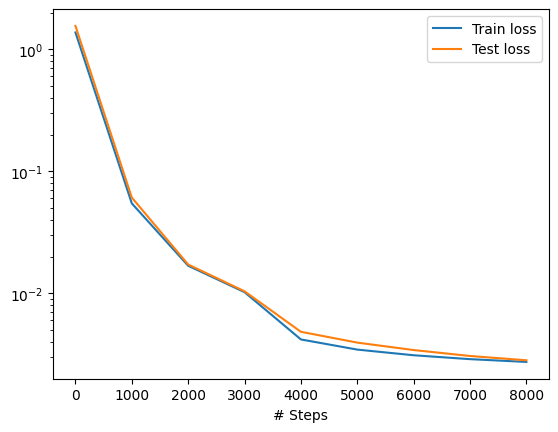

**Representative sample:**

<!-- ![representative sample](img/1b_sample.png) -->
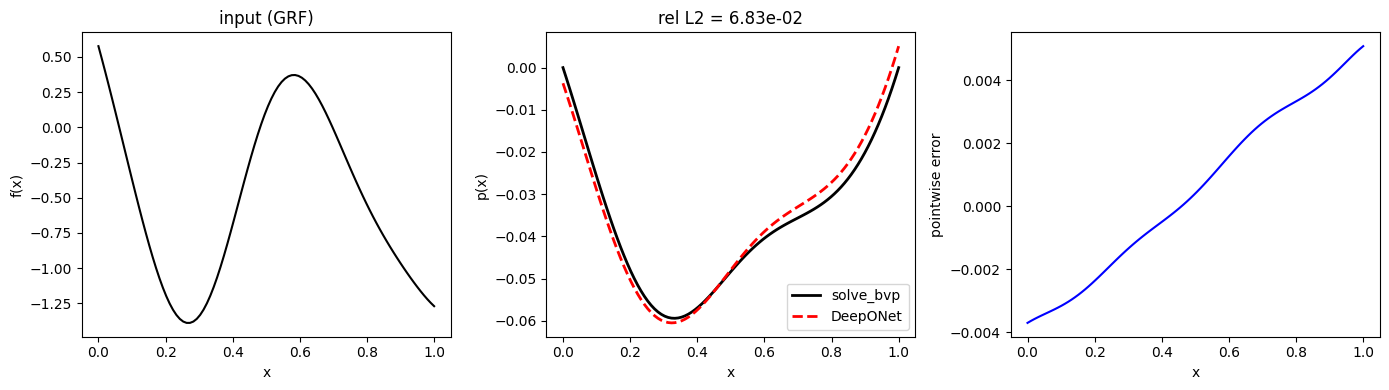

**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 6.83% |
| training samples | 1000 |
| iterations | 8000 |

---
# Step 2a: DeepONet, $\alpha \mapsto p$ with constant $\alpha$

**What is new:** the operator input switches from the source to the coefficient. $f = 1$ is now
fixed and $\alpha$ is drawn per sample from $\mathcal{U}[0.1, 5]$.

The analytical solution is the same formula, now read as a function of $\alpha$:

$$p(x) = \frac{x(1-x)}{2\alpha} \qquad\Longrightarrow\qquad p(0.5) = \frac{1}{8\alpha}$$

In Step 1 the operator was *linear* in its input: doubling $f$ doubles
$p$. Here $p$ scales as $1/\alpha$. This is the first genuinely nonlinear operator
in the ladder, and the $p \propto 1/\alpha$ curve is the check that the network has learned the
right nonlinearity rather than memorising an average.

**Implementation.** A small `ConstantAlpha` function space returns $\alpha$ at every sensor and
$\alpha' = 0$; the rest of the pipeline is identical to Step 2b.

**Colab notebook:** https://colab.research.google.com/drive/1H3eQwxEYe7SJFn58ntPFLeGrKXWjnwjF?usp=sharing

**Error curve:**

<!-- ![error curve](img/2a_error.png) -->
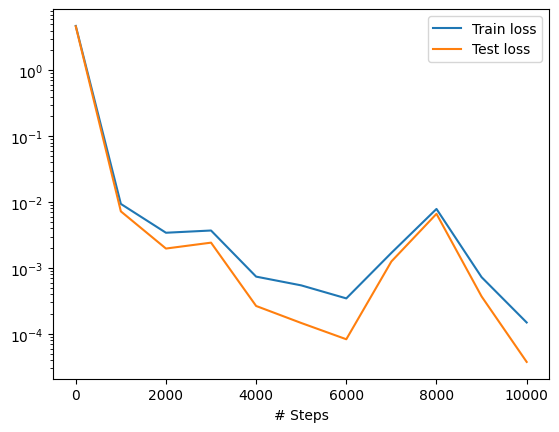

**Representative sample:**

<!-- ![representative sample](img/2a_sample.png) -->
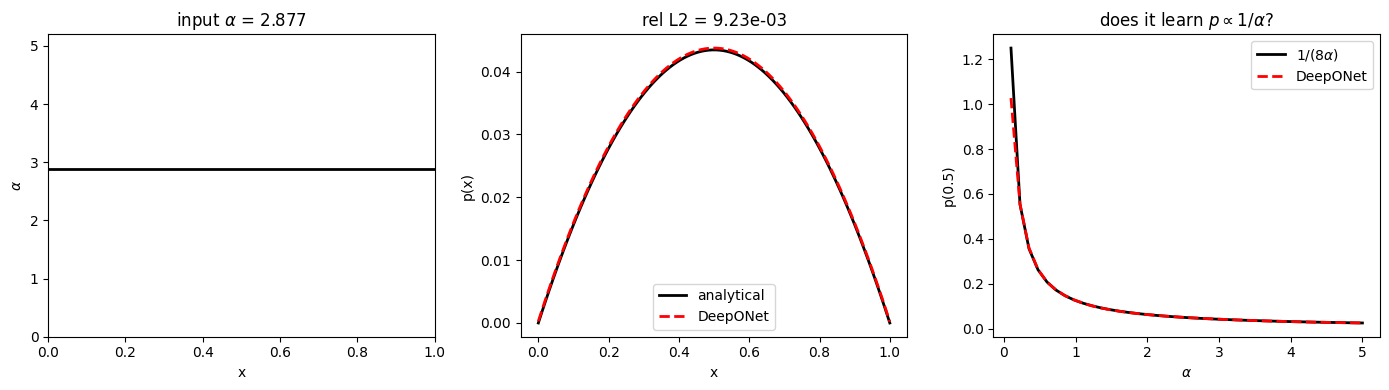

**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 0.92% |
| training samples | 1000 |
| iterations | 10,000 |

### Note

Here we canm clearly observe the inverse relation between $\alpha$ and p

---
# Step 2b: DeepONet, $\alpha(x) \mapsto p$ with spatially varying $\alpha$

**What is new:** $\alpha$ varies in space, so the product rule enters the residual.

$$-\frac{d}{dx}\left[\alpha(x) p'\right] - f \;=\; -\left(\alpha'(x)\,p' + \alpha(x)\,p''\right) - f$$

Both $\alpha$ and $\alpha'$ must therefore be supplied at every collocation point. They are
passed as DeepXDE auxiliary variables (Appendix A), with $\alpha'$ obtained by central
differencing the interpolated field.

**Positivity.** The problem is elliptic only where $\alpha > 0$. A zero-mean GRF takes negative
values over roughly half the domain, which makes the BVP ill-posed. The residual will still
decrease, so this does not announce itself as a failure. Map the field through a positive
function, e.g. $\alpha = \alpha_{\min} + e^{g}$ with $g$ the GRF; then $\alpha' = \alpha\,g'$.

**Verification.** Flux balance: integrating the equation over $[0,1]$ gives
$\alpha(1)p'(1) - \alpha(0)p'(0) = -\int_0^1 f\,dx = -1$.

**Colab notebook:** [click here](https://colab.research.google.com/drive/1Up6BKWkzVC3OFNv9satQXjT3lDFvS_f3?usp=sharing)

**Error curve:**

<!-- ![error curve](img/2b_error.png) -->
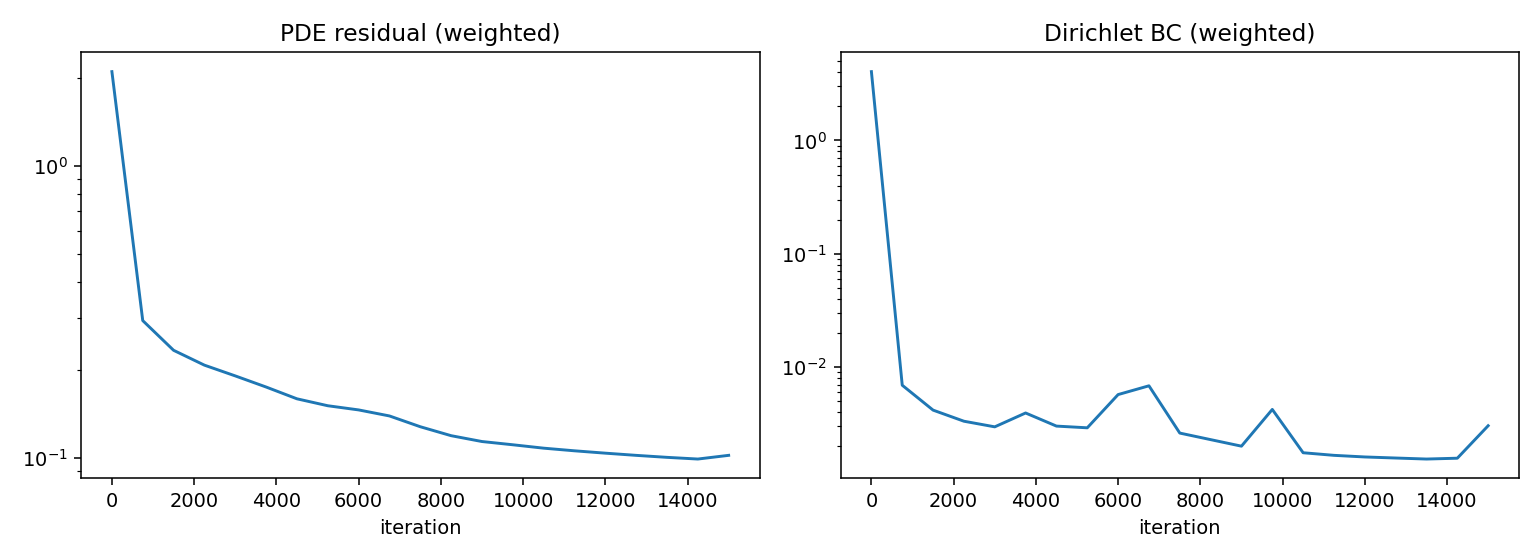


**Representative sample:**

<!-- ![representative sample](img/2b_sample.png) -->
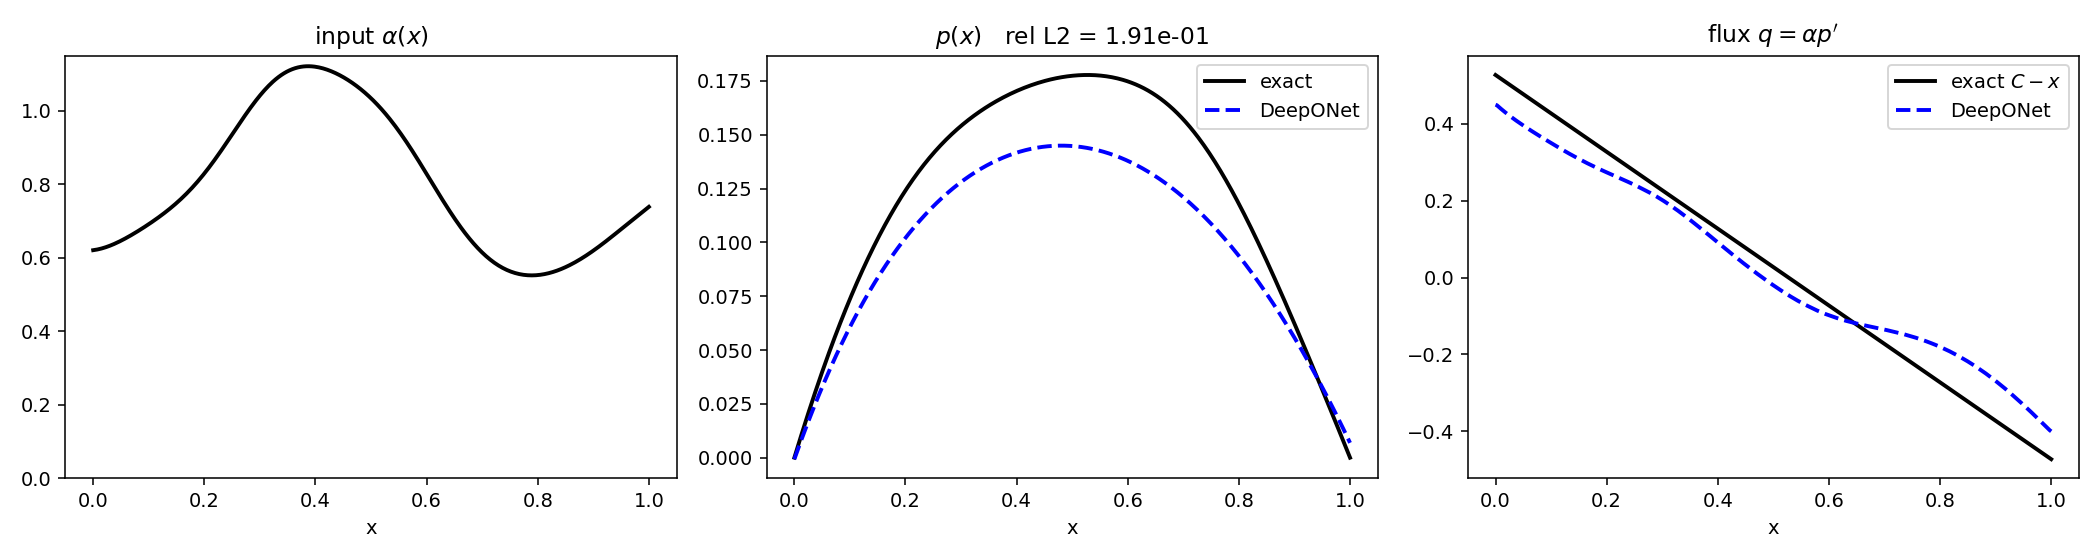


**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 19.07% |
| training samples | 1000 |
| iterations | 15,000 |

---
### Notes

The map $\alpha \mapsto p$ is harder than $f \mapsto p$ because the solution depends on $1/\alpha$:

$$
p(x) = \frac{x(1-x)}{2\alpha}
$$

and for spatially varying coefficients,

$$
p(x)=C\int_0^x \frac{ds}{\alpha(s)} - \int_0^x \frac{s\,ds}{\alpha(s)},
\qquad
C = \frac{\int_0^1 s\,\alpha^{-1}(s)\,ds}{\int_0^1 \alpha^{-1}(s)\,ds}.
$$

The inverse relation of $\alpha$ and p makes the operator nonlinear, nonlocal, and highly sensitive: small errors in $\alpha$ are amplified when $\alpha$ is small, and a local change can affect the solution across the whole domain. In contrast, $f \mapsto p$ is much more direct and forgiving. I had to decrease the learning rate by one order and increase the iterations by double. 

---
# Step 3b: $\phi$-DeepONet, piecewise constant $\alpha$ with an interface

**What is new:** a material interface at $x=0.5$ with $\alpha_1 \neq \alpha_2$. The solution
$p$ stays continuous but $p' = q/\alpha$ jumps, so $p$ has a **kink**. A standard DeepONet
cannot represent it: its trunk outputs are smooth basis functions, and their span contains no
kink at a prescribed location.

**Analytical solution** (Hansbo & Hansbo, 2002, §7.1) for $f=1$:

$$p_1(x) = \frac{(3\alpha_1+\alpha_2)\,x}{4\alpha_2 + 4\alpha_1\alpha_2} - \frac{x^2}{2\alpha_1},
\qquad
p_2(x) = \frac{\alpha_2-\alpha_1+(3\alpha_1+\alpha_2)x}{4\alpha_2+4\alpha_1\alpha_2} - \frac{x^2}{2\alpha_2}$$

Verify before generating anything: $p_1(0)=0$, $p_2(1)=0$, $p_1(0.5)=p_2(0.5)$,
$\alpha_1 p_1'(0.5) = \alpha_2 p_2'(0.5)$, and $-\alpha_q p_q'' = 1$ in each subdomain.

**The three $\phi$-DeepONet modifications** (Roy et al., 2026):

1. one branch network per subdomain, combined by an elementwise product;
2. a subdomain indicator embedded as an extra trunk input $\phi$, so the basis functions
   themselves can kink at the interface;
3. interface penalties in the loss.

$$\mathcal{L} = \mathcal{L}_{\text{PDE}} + \lambda_1 \underbrace{\left(p_1(0.5)-p_2(0.5)\right)^2}_{\text{continuity}} + \lambda_2 \underbrace{\left(\alpha_1 p_1'(0.5) - \alpha_2 p_2'(0.5)\right)^2}_{\text{flux}}$$

with $\lambda_1 = \lambda_2 = 10$ as a starting point and the gradients taken by autograd.

**Deliverable.** The three loss components plotted separately, interface errors reported
numerically, and a side-by-side comparison showing the standard DeepONet failing where
$\phi$-DeepONet succeeds.

**Colab notebook:** [click here](https://colab.research.google.com/drive/14dcwSzDkYAbvO78XJMhzrGQv49VbTSEy?usp=sharing)

**Architecture diagram:**

<!-- ![architecture](img/3b_arch.png) -->
_paste architecture image here_

**Error curve:**

<!-- ![error curve](img/3b_error.png) -->
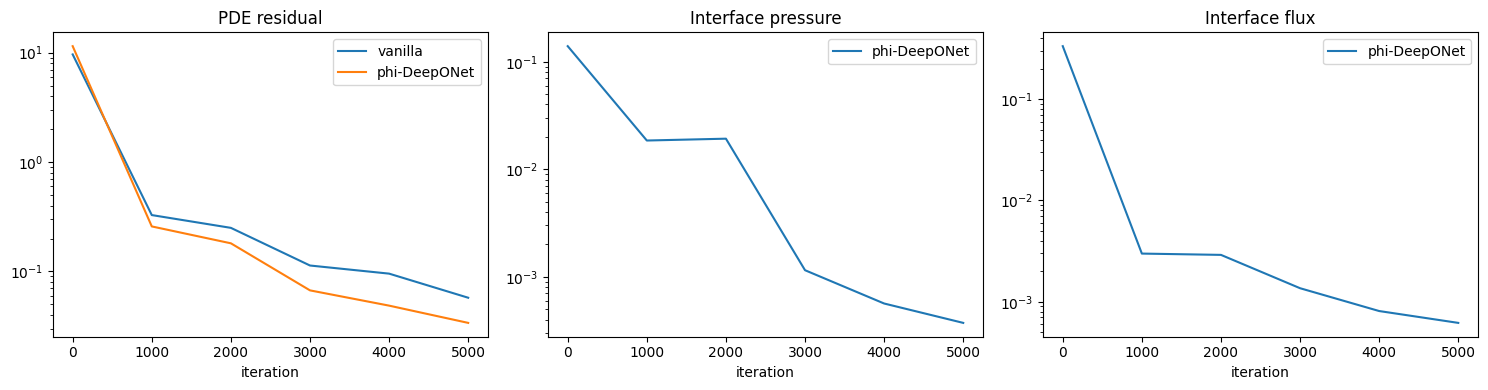

**Representative sample:**

<!-- ![representative sample](img/3b_sample.png) -->
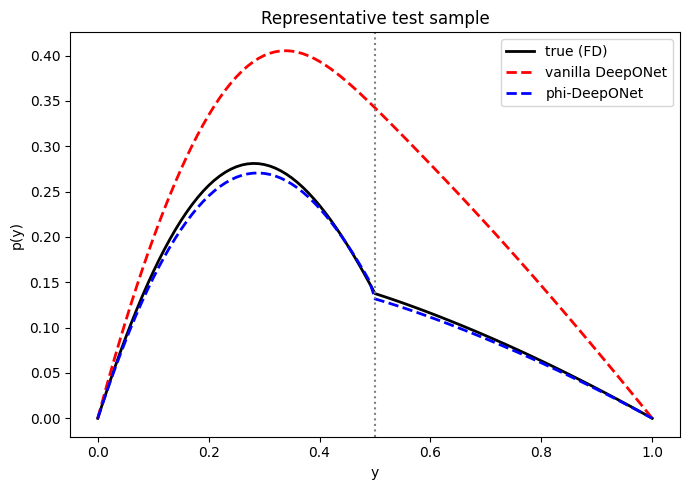

**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 7.09% |
| training samples | 1500 |
| iterations | 8000 |

---
# Step 3+: $\phi$-DeepONet, spatially varying $\alpha(x)$ with an interface

**What is new:** everything from 2b and 3b at once. $\alpha$ is smooth inside each subdomain,
jumps at $x=0.5$, and is the operator input; $f=1$ is fixed.

**Sampling $\alpha$.** Two independent GRFs, one per subdomain, mapped through an exponential
so the field is positive by construction, with the level in each subdomain drawn from disjoint
ranges so a jump is always present:

$$\alpha_q(x) = \exp\!\left(m_q + \sigma\, g_q(x)\right), \qquad g_q \sim \mathcal{GP}(0, k_{\ell_s})$$

The stored feature vector *is* $\alpha$ on a fixed node grid, so the branch sensor values, the
coefficients fed to the residual and the reference solution all interpolate the same array and
cannot drift apart.

**$\alpha'$ at the interface.** A central difference straddling $x=0.5$ sees the jump and
returns a huge spurious value, a smeared Dirac. Building one cubic spline per subdomain makes
$\alpha'$ exact and one-sided at the interface by construction.

**Architecture.** One branch per subdomain over its own sensors (sampled one-sided, so no
sensor value is drawn from across the jump); trunk takes $[x, \phi]$ with the scalar embedding
$\phi = \gamma_q = q$. Because $\phi$ is an *input* rather than a function of $x$, the trunk can
be evaluated twice at exactly $x = 0.5$, once per subdomain label, so the interface residuals
are exact rather than $O(\delta)$ approximations at $0.5 \mp \delta$.

**Reference solution.** For $f=1$ the closed form above applies with $\alpha$ replaced by the
sampled field, the two integrals taken separately on each subdomain so the jump in $1/\alpha$ is
never integrated through. This is exact up to quadrature error and needs no BVP solver.

**Correctness check.** With $\alpha$ piecewise *constant*, Step 3+ must reproduce Step 3b to
within a factor of 2.

**Colab notebook:** [click here](https://colab.research.google.com/drive/1r18mTtEUkMPjUBlMFzjqgiKNs5e9nUzc)

**Error curve:**

<!-- ![error curve](img/3plus_error.png) -->
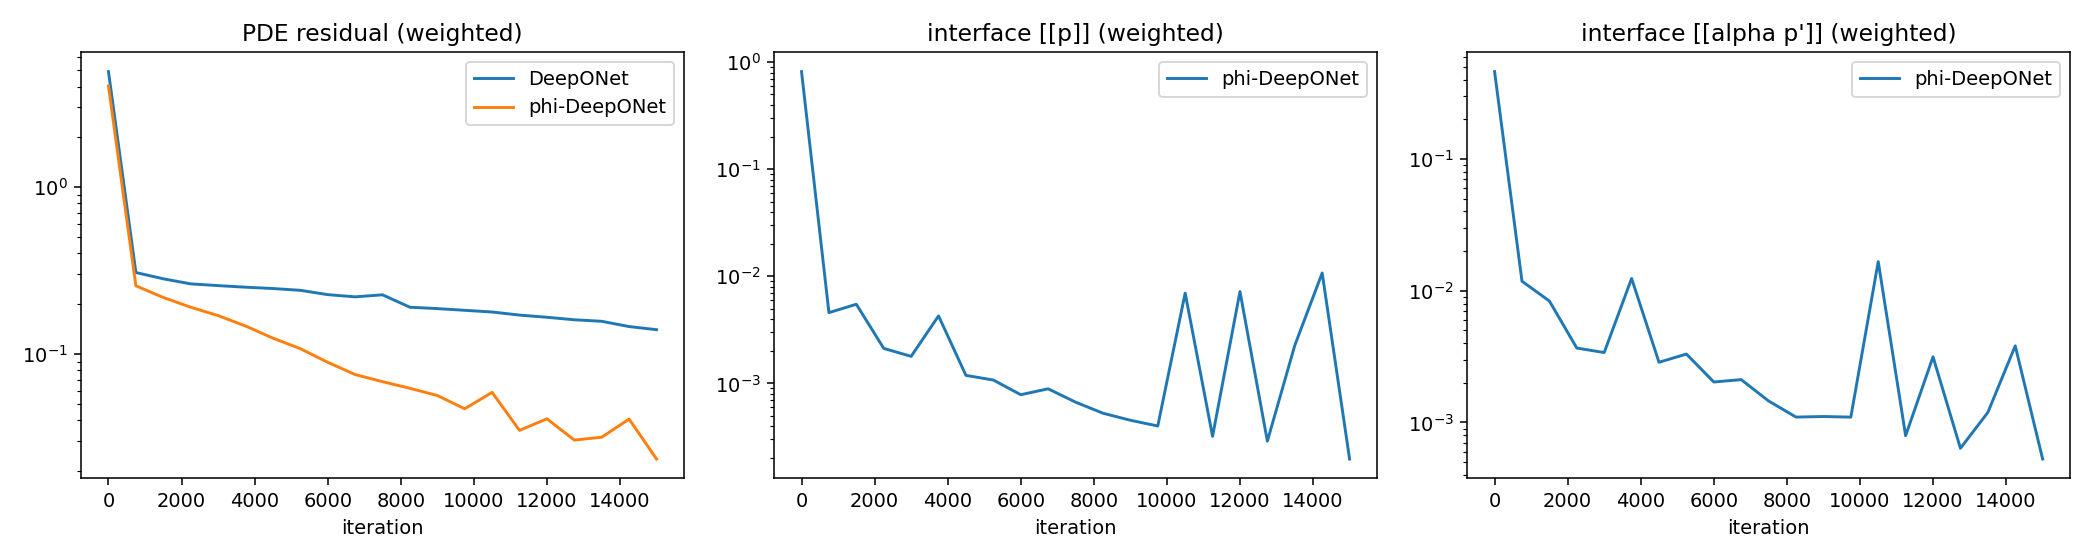

**Representative sample:**

<!-- ![representative sample](img/3plus_sample.png) -->
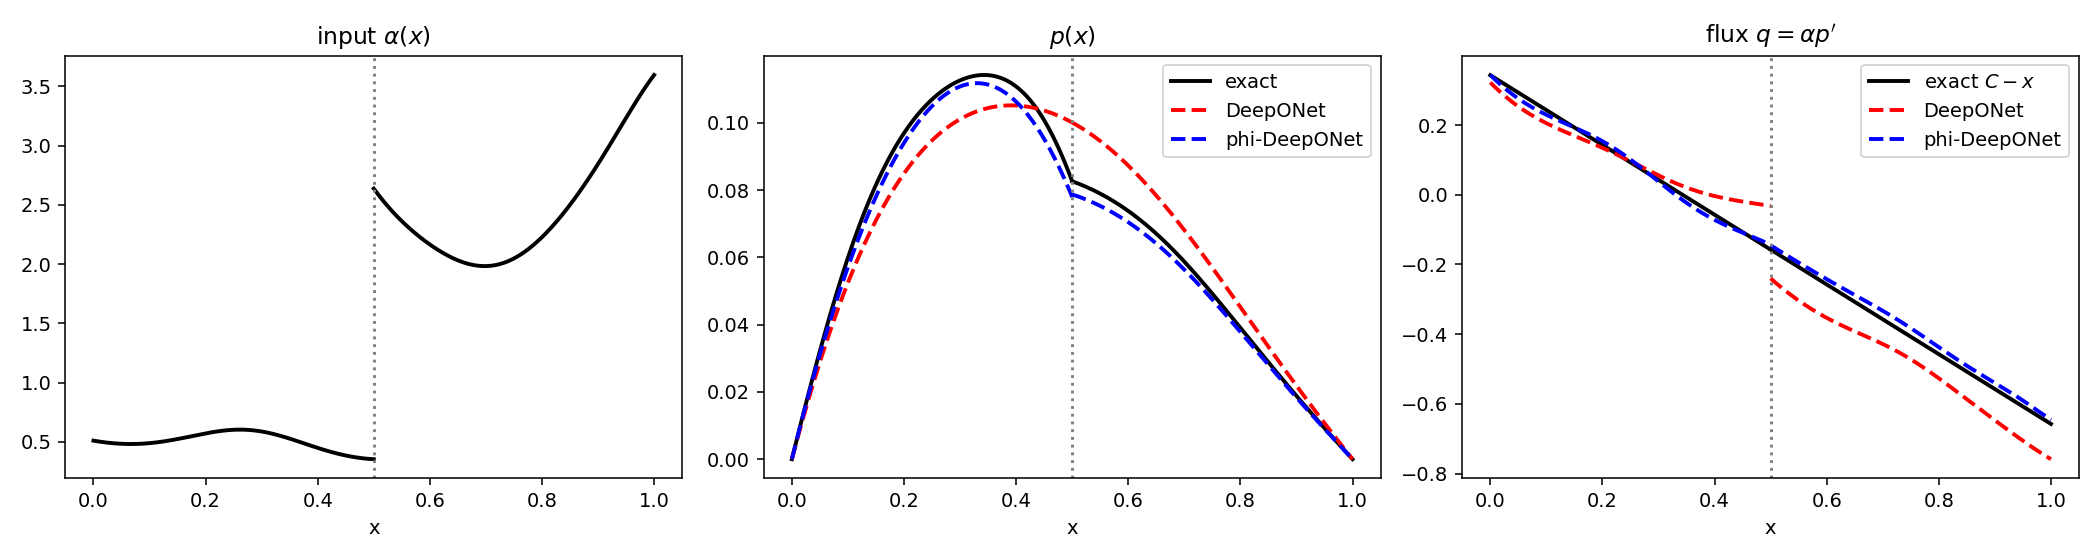

**Results**

| quantity | value |
|---|---|
| mean rel. $L_2$ (200 test samples) | 4.34% |
| training samples | 1000 |
| iterations | 15000 |

---
# Appendix A: How data generation works inside DeepXDE

Nothing in Steps 1–3+ is a supervised dataset. The pieces below are what DeepXDE assembles
behind `model.train()`.

## A.1 `FunctionSpace`: where the input functions come from

A function space supplies the random input functions. Its contract is two methods:

- `random(size)` → a `(size, n_features)` array of **features**, the compressed representation
  of each sampled function (for `GRF`, the field values on an internal grid; for
  `PowerSeries`, the polynomial coefficients);
- `eval_batch(features, xs)` → a `(size, len(xs))` array of function values at the points `xs`.

Built-in spaces include `GRF`, `PowerSeries` and `Chebyshev`. Subclassing is how the ladder
extends: `GRFWithDerivative` adds `eval_batch_derivative` for $\alpha'$, `ConstantAlpha`
returns a scalar per sample, and the Step 3+ space returns two independent fields with a jump.

## A.2 `dde.data.PDE`: the collocation points and the residual

`dde.data.PDE(geometry, residual, bcs, num_domain, num_boundary, anchors, num_test)` samples
the points at which the physics is enforced and assembles

```
train_x = [ BC points ... ; domain points ... ]
num_bcs = [ number of points contributed by each BC ]
```

The BC points come first, which is why every loss routine slices with a cumulative sum of
`num_bcs`. `anchors` lets you supply the collocation points explicitly instead of sampling them: used in Step 3+ to keep every residual point strictly inside one subdomain, since the
expanded residual is invalid where $\alpha$ is discontinuous.

## A.3 `dde.data.PDEOperator`: one PDE per sampled function

`PDEOperator(pde, function_space, evaluation_points, num_function, num_test)` turns a
single-instance PDE into an operator-learning problem. `evaluation_points` are the **sensors**:
their number fixes the branch network's input width.

For each of the `num_function` sampled functions, the same collocation points are reused, and
the arrays are laid out row-wise:

```
gen_inputs(features, values, points) ->
    v  = np.repeat(values, len(points), axis=0)     # branch input, one row per (function, point)
    x  = np.tile(points, (len(features), 1))        # trunk input
    vx = func_space.eval_batch(features, points)    # auxiliary variables at each point
```

so the branch vector is duplicated once per collocation point. `num_bcs` is scaled by
`num_function`, which is why a `PointSetOperatorBC` target array must have
`n_points × num_function` rows.

## A.4 Auxiliary variables: getting $\alpha$ into the residual

The residual signature is `pde(x, y, aux)`. Whatever `gen_inputs` returns as `vx` arrives as
`aux`, aligned row for row with the collocation points. Steps 2b onward return two columns,
$[\alpha(x), \alpha'(x)]$, because the expanded residual needs both. This is the mechanism that
lets a *coefficient* vary per sample without ever being seen by the trunk network.

One limitation matters at the interface: `PointSetOperatorBC` calls its function as
`func(inputs, outputs, X)` and never receives `aux`, and the `X` DeepXDE passes is the
*training* array even during testing. In Step 3+ the coefficient is therefore carried as extra
columns of the trunk input instead, so the flux condition can read this sample's
$\alpha_1(0.5)$ and $\alpha_2(0.5)$.

## A.5 Boundary conditions

Two options, both used here:

- **soft**: `dde.icbc.DirichletBC` adds $\left(p(0)^2 + p(1)^2\right)$ as a loss term;
- **hard**: reparameterise the output as $p = x(1-x)\,\hat{p}$, so $p(0)=p(1)=0$ holds by
  construction and the boundary loss disappears entirely (Eq. 14 of the $\phi$-DeepONet paper;
  see Sukumar & Srivastava, 2022, for the general construction).

## A.6 Where reference solutions enter

Only in testing. `scipy.solve_bvp` (Steps 1b, 2b) and the closed-form quadrature (Step 3+)
generate ground truth for held-out samples so that a relative $L_2$ error can be quoted. No
solver output is ever used in a training loss.

---
# Appendix B: Why the flux need not appear explicitly

The divergence form contains the flux $q = \alpha p'$ explicitly:

$$-\frac{dq}{dx} = f, \qquad q = \alpha p'.$$

One could learn $(p, q)$ as two network outputs, a mixed formulation, and impose both
equations. That is never necessary here, for two reasons.

**1. Autodiff plus a known $\alpha'$ closes the product rule.** Expanding,

$$-\frac{d}{dx}\left[\alpha p'\right] = -\left(\alpha' p' + \alpha p''\right),$$

every term is available: $p'$ and $p''$ from automatic differentiation of the network, and
$\alpha, \alpha'$ from the function space, which knows the sampled coefficient analytically (or
by spline differentiation). The flux is never needed as a stored variable, so a single-output
network suffices. A mixed formulation would add a second output, a second residual and an extra
loss weight for no gain.

**2. Within a subdomain the flux carries no extra information.** $q$ is a *derived* quantity;
imposing $q = \alpha p'$ as a constraint would be imposing a definition.

**The one place where it does not hold.** Expanding the divergence form deletes the flux from
the equation, and the deleted quantity is exactly the one the interface condition constrains.
Inside each subdomain that is harmless. Across the interface it is not: on $\Omega_1$ alone,
the PDE plus the single Dirichlet condition at $x=0$ leaves the one-parameter family
$\alpha p' = C - x$ with $C$ free, and only $[\![\alpha p']\!] = 0$ selects the right member.
This is why the flux term in $\mathcal{L}_{\text{I}}$ is not optional and cannot be inferred
from the residual — it is the only equation coupling the two subdomains.

Measured in Step 3+: the interface-blind DeepONet reaches rms $[\![\alpha p']\!] \approx 2
\times 10^{-1}$, against $\approx 1 \times 10^{-2}$ for $\phi$-DeepONet on the same data.

**A note on $\lambda_1, \lambda_2$.** Because the interface conditions are enforced softly, the
weights trade against the residual. Raising them by an order of magnitude reduced the jumps
slightly but degraded the residual and roughly doubled the $L_2$ error. The three loss
components should be watched separately and rebalanced, rather than set once and forgotten;
this soft enforcement is a limitation the $\phi$-DeepONet paper itself notes.

---
# References

**Papers**

1. L. Lu, P. Jin, G. Pang, Z. Zhang, G. E. Karniadakis. *Learning nonlinear operators via
   DeepONet based on the universal approximation theorem of operators.* Nature Machine
   Intelligence **3**(3), 218–229, 2021.
2. T. Chen, H. Chen. *Universal approximation to nonlinear operators by neural networks with
   arbitrary activation functions and its application to dynamical systems.* IEEE Transactions
   on Neural Networks **6**(4), 911–917, 1995.
3. S. Roy, S. Castonguay, P. Roy, M. D. Shields. *$\phi$-DeepONet: a discontinuity capturing
   neural operator.* arXiv:2604.08076, 2026.
4. A. Hansbo, P. Hansbo. *An unfitted finite element method, based on Nitsche's method, for
   elliptic interface problems.* Computer Methods in Applied Mechanics and Engineering
   **191**, 5537–5552, 2002. (§7.1 for the analytical solution.)
5. S. Wang, H. Wang, P. Perdikaris. *Learning the solution operator of parametric partial
   differential equations with physics-informed DeepONets.* Science Advances **7**(40),
   eabi8605, 2021.
6. P. Jin, S. Meng, L. Lu. *MIONet: learning multiple-input operators via tensor product.*
   SIAM Journal on Scientific Computing **44**(6), A3490–A3514, 2022. (Multiple branch
   networks combined by a product.)
7. W.-F. Hu, T.-S. Lin, M.-C. Lai. *A discontinuity capturing shallow neural network for
   elliptic interface problems.* Journal of Computational Physics **469**, 111576, 2022.
   (The augmented-input idea behind $\phi$.)
8. S. Wu, A. Zhu, Y. Tang, B. Lu. *Solving parametric elliptic interface problems via
   interfaced operator network.* Journal of Computational Physics **514**, 113217, 2024.
   (IONet, the domain-decomposition alternative.)
9. N. Sukumar, A. Srivastava. *Exact imposition of boundary conditions with distance functions
   in physics-informed deep neural networks.* CMAME **389**, 114333, 2022.

**Software**

11. L. Lu, X. Meng, Z. Mao, G. E. Karniadakis. *DeepXDE: a deep learning library for solving
    differential equations.* SIAM Review **63**(1), 208–228, 2021.
    Documentation: https://deepxde.readthedocs.io
12. `scipy.integrate.solve_bvp` —
    https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_bvp.html
13. PyTorch autograd —
    https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html